In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [30]:
# Dataset

# Read Kaggle dataset
df = pd.read_csv("demand-forecasting-kernels-only/train.csv")
df


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10
...,...,...,...,...
912995,2017-12-27,10,50,63
912996,2017-12-28,10,50,59
912997,2017-12-29,10,50,74
912998,2017-12-30,10,50,62


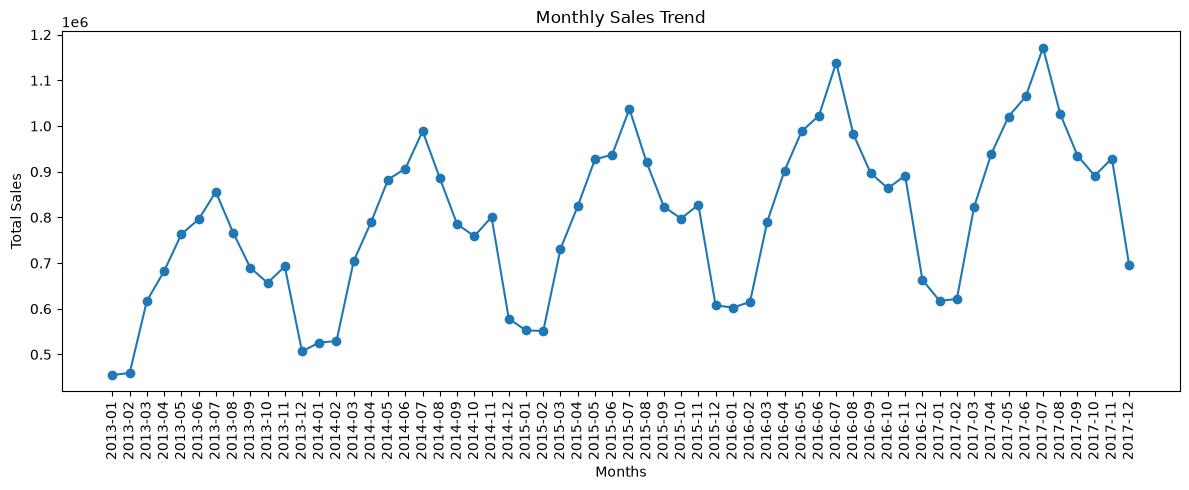

In [22]:
# Task1:Line plot sales trend

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])
#df.head()

# Group sales by month
monthly_sales = df.groupby(df["date"].dt.to_period("M"))["sales"].sum()

# Plot using Matplotlib only
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Months")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()





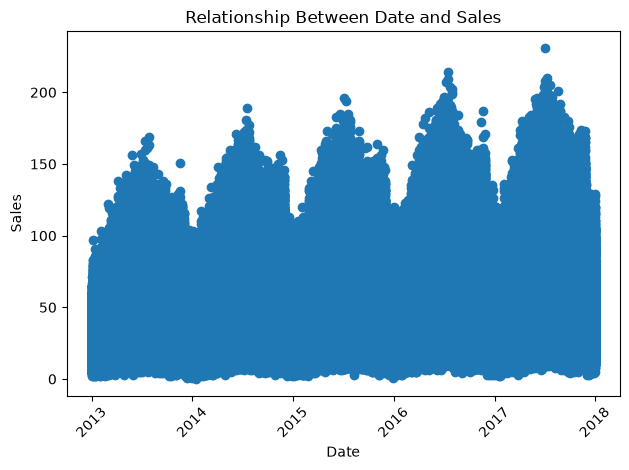

In [23]:
# Task2: Scatter plot 

# Create scatter plot
plt.scatter(df["date"], df["sales"])

# Add title and labels
plt.title("Relationship Between Date and Sales")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


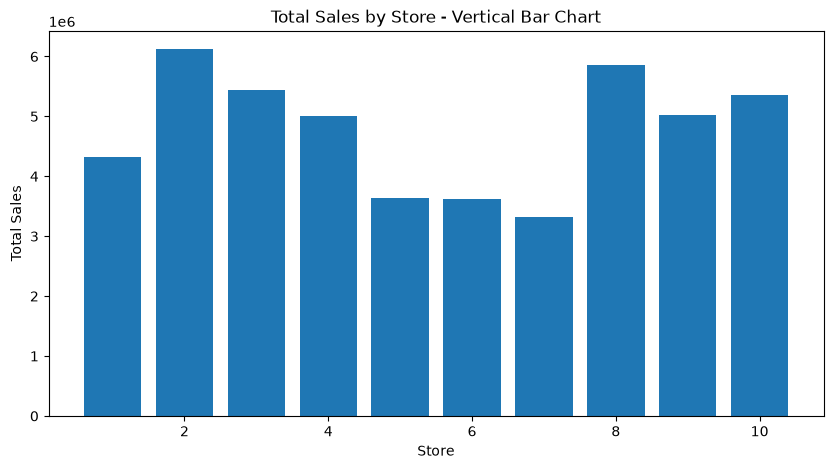

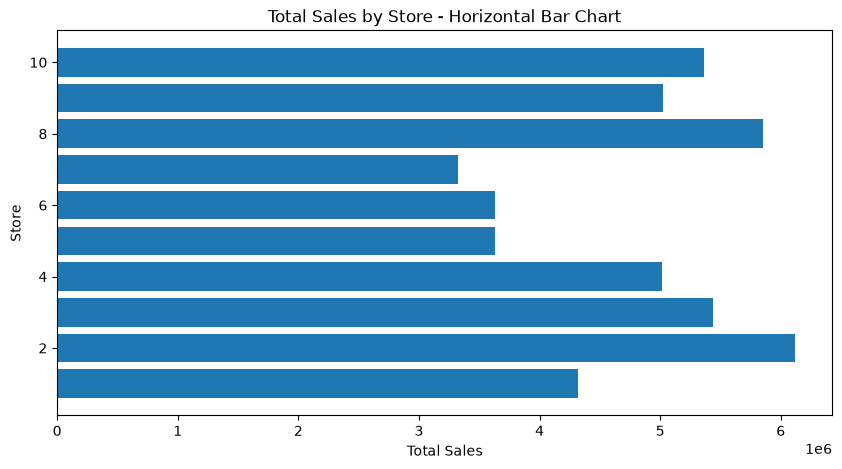

In [24]:
# Task 3: bar plot

# Calculate total sales for each store
store_sales = df.groupby("store")["sales"].sum()

# Vertical bar chart
plt.figure(figsize=(10, 5))
plt.bar(store_sales.index, store_sales.values)

plt.title("Total Sales by Store - Vertical Bar Chart")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.show()

#  Horizontal bar chart
plt.figure(figsize=(10, 5))
plt.barh(store_sales.index, store_sales.values)

plt.title("Total Sales by Store - Horizontal Bar Chart")
plt.xlabel("Total Sales")
plt.ylabel("Store")
plt.show()


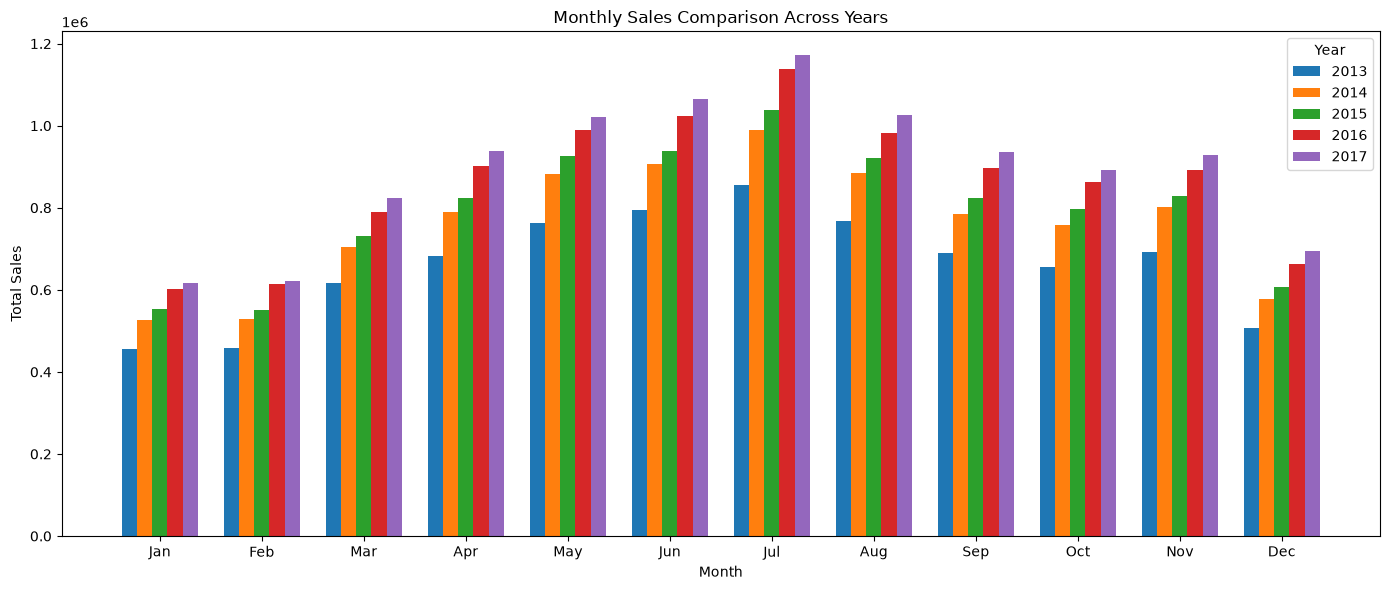

In [25]:
# Task4: Multi barplot

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"])

# Extract year and month
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# Calculate total sales for each month of each year
monthly_sales = df.groupby(["year", "month"])["sales"].sum().unstack(level=0)

# Set bar positions
months = np.arange(1, 13)
years = monthly_sales.columns
bar_width = 0.15

# Create grouped bar chart
plt.figure(figsize=(14, 6))

for i, year in enumerate(years):
    positions = months + (i - (len(years) - 1) / 2) * bar_width
    plt.bar(
        positions,
        monthly_sales[year].reindex(months, fill_value=0),
        width=bar_width,
        label=str(year),
        align="center"
    )

# Add title, labels and legend
plt.title("Monthly Sales Comparison Across Years")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(months, [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])
plt.legend(title="Year")

plt.tight_layout()
plt.show()


[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

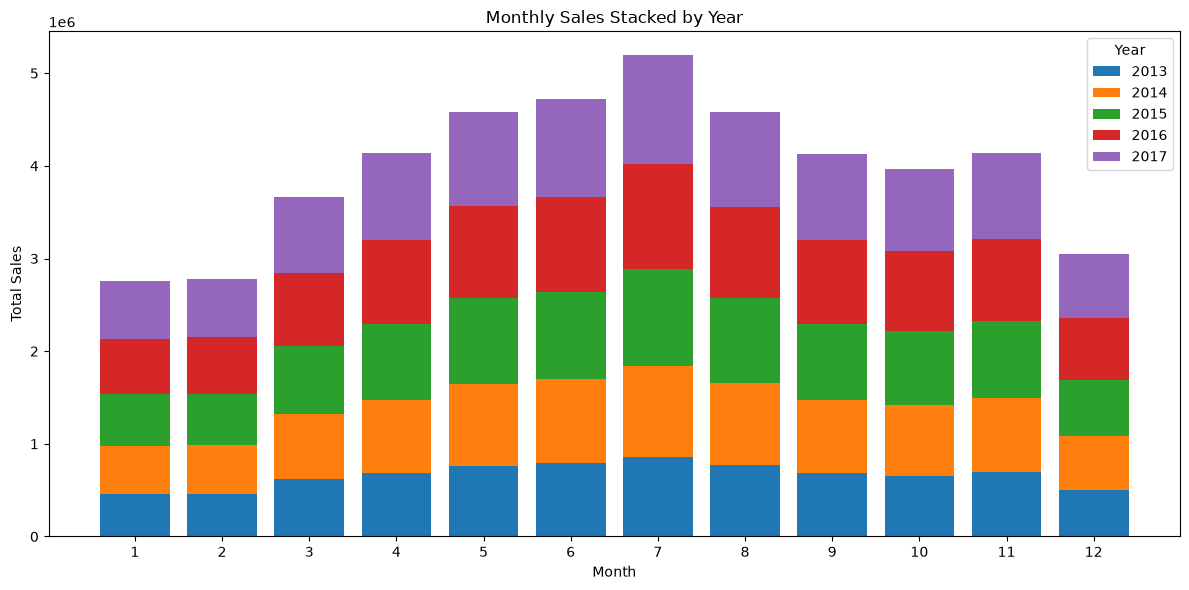

In [26]:
#  Task5: Stacked bar

# Extract year and month
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# Group sales by month and year
monthly_sales = df.groupby(["month", "year"])["sales"].sum().unstack(fill_value=0)

# Create stacked bar chart
plt.figure(figsize=(12, 6))

bottom = [0] * 12
display(bottom)

for year in monthly_sales.columns:
    sales = monthly_sales[year].tolist()

    plt.bar(monthly_sales.index, sales, bottom=bottom, label=str(year))

    for i in range(12):
        bottom[i] = bottom[i] + sales[i]

# Add title, labels and legend
plt.title("Monthly Sales Stacked by Year")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.tight_layout()
plt.show()


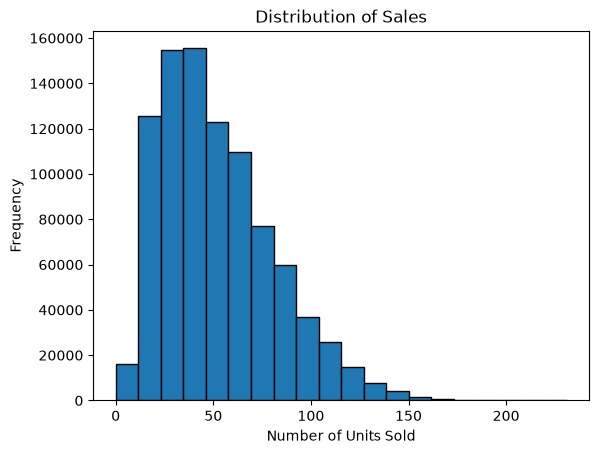

In [27]:
# Task6: Marks distributions
# Create histogram
plt.hist(df['sales'], bins=20, edgecolor='black')

# Add title and labels
plt.title("Distribution of Sales")
plt.xlabel("Number of Units Sold")
plt.ylabel("Frequency")

plt.show()



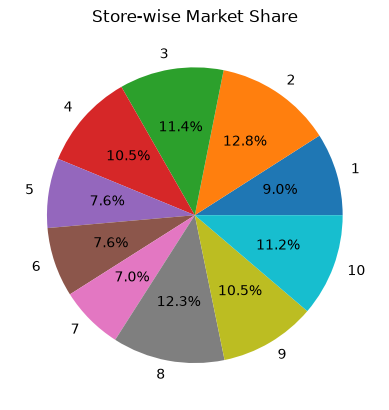

In [28]:
# Task7: Min project

# Calculate total sales for each store
store_sales = df.groupby('store')['sales'].sum()
store_sales
# Create pie chart
plt.pie(store_sales,labels=store_sales.index,autopct='%1.1f%%')

# Add title
plt.title("Store-wise Market Share")

plt.show()